In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.preprocessing import StandardScaler,LabelEncoder,OneHotEncoder,OrdinalEncoder
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
import pickle
from sklearn.pipeline import Pipeline

In [ ]:
data=pd.read_csv("/content/heart.csv")

In [ ]:
data

,\tAge,Gender,Chest pain type,Resting blood pressure,Cholesterol,Fasting blood sugar,Resting ECG,Maximum heart rate,Exercise-induced angina,ST depression,Slope,Number of major vessels,Thalassemia,output
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0


In [ ]:
data.head()

,\tAge,Gender,Chest pain type,Resting blood pressure,Cholesterol,Fasting blood sugar,Resting ECG,Maximum heart rate,Exercise-induced angina,ST depression,Slope,Number of major vessels,Thalassemia,output
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [ ]:
data.tail()

,\tAge,Gender,Chest pain type,Resting blood pressure,Cholesterol,Fasting blood sugar,Resting ECG,Maximum heart rate,Exercise-induced angina,ST depression,Slope,Number of major vessels,Thalassemia,output
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0
302,57,0,1,130,236,0,0,174,0,0.0,1,1,2,0


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   	Age                     303 non-null    int64  
 1   Gender                   303 non-null    int64  
 2   Chest pain type          303 non-null    int64  
 3   Resting blood pressure   303 non-null    int64  
 4   Cholesterol              303 non-null    int64  
 5   Fasting blood sugar      303 non-null    int64  
 6   Resting ECG              303 non-null    int64  
 7   Maximum heart rate       303 non-null    int64  
 8   Exercise-induced angina  303 non-null    int64  
 9   ST depression            303 non-null    float64
 10  Slope                    303 non-null    int64  
 11  Number of major vessels  303 non-null    int64  
 12  Thalassemia              303 non-null    int64  
 13  output                   303 non-null    int64  
dtypes: float64(1), int64(13)
m

In [ ]:
data.describe()

,\tAge,Gender,Chest pain type,Resting blood pressure,Cholesterol,Fasting blood sugar,Resting ECG,Maximum heart rate,Exercise-induced angina,ST depression,Slope,Number of major vessels,Thalassemia,output
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [ ]:
data.shape

(303, 14)

In [ ]:
data.isnull().sum()

,0
\tAge,0
Gender,0
Chest pain type,0
Resting blood pressure,0
Cholesterol,0
Fasting blood sugar,0
Resting ECG,0
Maximum heart rate,0
Exercise-induced angina,0
ST depression,0


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


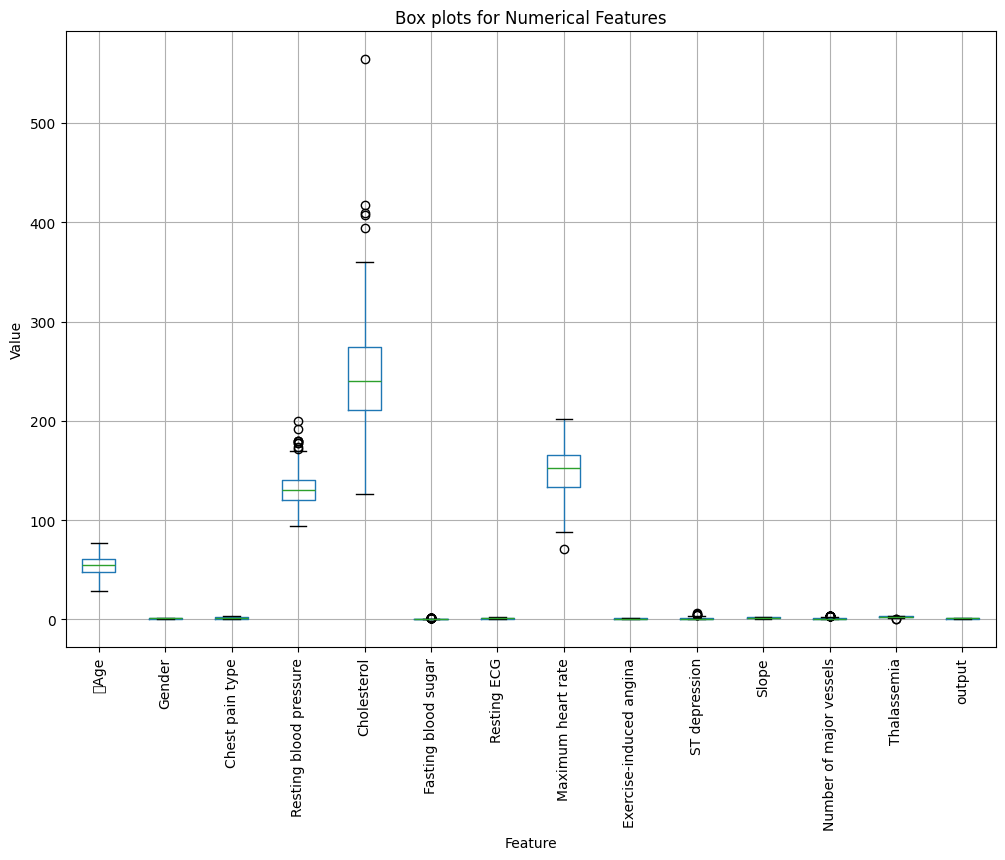

In [ ]:
numerical_cols = data.select_dtypes(include=['int','float']).columns
plt.figure(figsize=(12, 8))
data[numerical_cols].boxplot()
plt.xticks(rotation=90)
plt.title('Box plots for Numerical Features')
plt.ylabel('Value')
plt.xlabel('Feature')
plt.show()

/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.draw()


<Axes: >

/usr/local/lib/python3.13/dist-packages/IPython/core/events.py:89: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


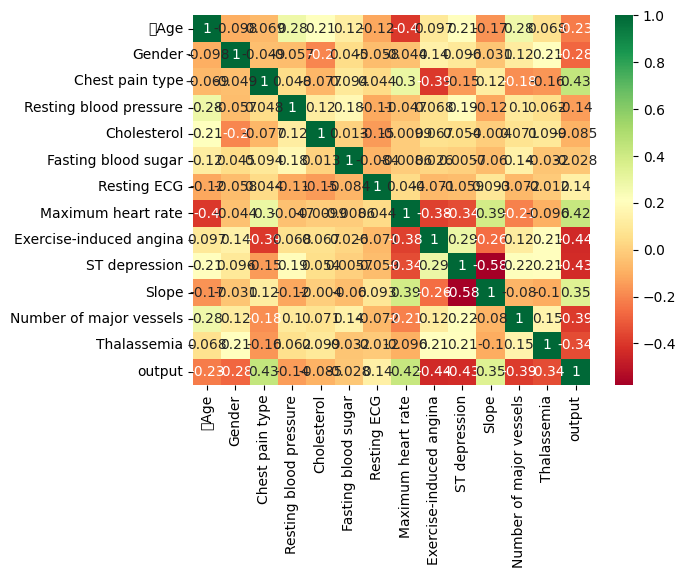

In [ ]:
sns.heatmap(data.select_dtypes(include=['int','float']).corr(),cmap="RdYlGn",annot=True)

In [ ]:
np.where(data.select_dtypes(include=['int', 'float']).corr()>0.9)

(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13]),
 array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13]))

In [ ]:
data.columns

Index(['\tAge', 'Gender', 'Chest pain type', 'Resting blood pressure',
       'Cholesterol', 'Fasting blood sugar', 'Resting ECG',
       'Maximum heart rate', 'Exercise-induced angina', 'ST depression',
       'Slope', 'Number of major vessels', 'Thalassemia', 'output'],
      dtype='object')

In [ ]:
x = data.drop("output", axis=1)
y = data["output"]

In [ ]:
y

,output
0,1
1,1
2,1
3,1
4,1
...,...
298,0
299,0
300,0
301,0


In [ ]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()

x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)

In [ ]:
from sklearn.svm import SVC

svclassifier = SVC()

svclassifier.fit(x_train, y_train)

SVC()

In [ ]:
y_pred = svclassifier.predict(x_test)

In [ ]:
from sklearn.metrics import accuracy_score

print(accuracy_score(y_test, y_pred))

0.8064516129032258


Hyper tuning process

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

In [ ]:
param_grid = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf', 'poly'],
    'gamma': ['scale', 'auto']
}

In [ ]:
svclassifier = SVC()

In [ ]:
grid_search = GridSearchCV(
    svclassifier,
    param_grid,
    cv=5,
    scoring='accuracy'
)

grid_search.fit(x_train, y_train)


GridSearchCV(cv=5, estimator=SVC(),
             param_grid={'C': [0.1, 1, 10, 100], 'gamma': ['scale', 'auto'],
                         'kernel': ['linear', 'rbf', 'poly']},
             scoring='accuracy')

In [ ]:
grid_search.best_params_

{'C': 100, 'gamma': 'scale', 'kernel': 'linear'}

In [ ]:
grid_search.best_score_

np.float64(0.8381818181818183)

In [ ]:
best_model = grid_search.best_estimator_

In [ ]:
y_pred = best_model.predict(x_test)

In [ ]:
from sklearn.metrics import accuracy_score

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.8387096774193549


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.88      0.83      0.86        18
           1       0.79      0.85      0.81        13

    accuracy                           0.84        31
   macro avg       0.83      0.84      0.84        31
weighted avg       0.84      0.84      0.84        31

